# Sprint 3: GraphSAGE structural-deprivation head

Proposal Sec 3.4.3 (weeks 5–6): train the two-layer GraphSAGE network on Kibera deprivation node labels and hit **macro-F1 ≥ 0.60** on the stratified validation split.

**What this notebook does**

1. Loads (or rebuilds) the Sprint 1 proximity graph from OSM buildings + infrastructure distances.
2. Attaches a three-class UN-Habitat / SUPI-**proxy** deprivation label (`src/utils/deprivation_label.py`) — continuous indicator scores cut into settlement-relative tertiles.
3. Trains `GraphSAGEModel` (Adam lr=`5e-3`, weight decay=`5e-4`, stratified 60/20/20) and reports macro-F1.
4. Saves the best checkpoint for Sprint 5 late fusion.

**About the label.** There is no household survey ground truth in this repo. The class target is an OSM-derived proxy of durability, water/sanitation/road access, and footprint overcrowding. Treat Sprint 3 metrics as *can the GNN learn the proxy*, not as a claim about true SUPI accuracy. Replace the label constructor when field labels exist.

**NRRP note.** Flood-label validation against the NRRP 37 high-risk zones is wired in Sprint 2 v2 (`label_validation.py`) but needs the NRRP polygons (or the OSM river-corridor fallback) run in Colab. Per the proposal, *policy* validation against NRRP is Sprint 5 (fusion engine). Do not block Sprint 3 on it.

## 0. Before you run

- **Runtime → Change runtime type → T4 GPU** (optional; the Kibera graph trains fine on CPU).
- Sprint 1 must have produced `data/graphs/kibera_graph.pt`, **or** this notebook will rebuild the graph live via osmnx (needs Overpass).
- Push the Sprint 3 source (`src/models/graphsage*.py`, `src/utils/deprivation_label.py`) to GitHub before cloning here.

In [1]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU — GraphSAGE on Kibera is small enough for CPU.")

CUDA available: True
GPU: Tesla T4


In [1]:
%%bash
# Sprint 3 lives on this branch until PR #6 is merged to main.
BRANCH=cursor/sprint3-graphsage-deprivation-815d
cd /content
if [ -d nairobi-risk-mapping ]; then
  cd nairobi-risk-mapping
  git fetch origin "$BRANCH"
  git checkout "$BRANCH"
  git pull origin "$BRANCH"
else
  git clone -b "$BRANCH" https://github.com/emmanuelamor5/nairobi-risk-mapping.git
fi
cd /content/nairobi-risk-mapping && git rev-parse --abbrev-ref HEAD && ls src/utils/deprivation_label.py

Your branch is up to date with 'origin/cursor/sprint3-graphsage-deprivation-815d'.
Already up to date.
cursor/sprint3-graphsage-deprivation-815d
src/utils/deprivation_label.py


From https://github.com/emmanuelamor5/nairobi-risk-mapping
 * branch            cursor/sprint3-graphsage-deprivation-815d -> FETCH_HEAD
Already on 'cursor/sprint3-graphsage-deprivation-815d'
From https://github.com/emmanuelamor5/nairobi-risk-mapping
 * branch            cursor/sprint3-graphsage-deprivation-815d -> FETCH_HEAD


In [2]:
%cd /content/nairobi-risk-mapping
!pip install -q -r requirements.txt

/content/nairobi-risk-mapping


In [3]:
# --- config knobs ---
SETTLEMENT_KEY = "kibera"
REBUILD_GRAPH = False  # True forces a fresh osmnx pull even if a .pt exists
EPOCHS = 100
LEARNING_RATE = 5e-3
WEIGHT_DECAY = 5e-4
EARLY_STOPPING_PATIENCE = 20
CHECKPOINT_DIR = "checkpoints/sprint3_graphsage"
SEED = 42

## 1. Repo check — Sprint 3 APIs exist

In [4]:
from src import config
from src.utils.deprivation_label import NODE_FEATURE_NAMES, class_distribution
from src.models.graphsage import GraphSAGE
from src.models.graphsage_model import GraphSAGEModel
from src.models.graphsage_metrics import stratified_node_split

assert len(NODE_FEATURE_NAMES) == 5
assert config.GRAPHSAGE_SPRINT3_MACRO_F1_TARGET == 0.60
print("Node features:", NODE_FEATURE_NAMES)
print("Sprint 3 macro-F1 target:", config.GRAPHSAGE_SPRINT3_MACRO_F1_TARGET)
print("Classes:", config.DEPRIVATION_CLASS_NAMES)

Node features: ('area_m2', 'dist_to_water_m', 'dist_to_sanitation_m', 'dist_to_road_m', 'roof_material_score')
Sprint 3 macro-F1 target: 0.6
Classes: ('low', 'medium', 'high')


## 2. Load or rebuild the settlement graph

If `data/graphs/{settlement}_graph.pt` was saved by an older Sprint 1 run **without** `data.y` deprivation labels, set `REBUILD_GRAPH = True` so `DataPipeline.acquire_graph_data()` re-enriches buildings and re-serialises.

In [6]:
%cd /content/nairobi-risk-mapping
!git fetch origin cursor/sprint3-graphsage-deprivation-815d
!git checkout cursor/sprint3-graphsage-deprivation-815d
!git pull origin cursor/sprint3-graphsage-deprivation-815d

# drop cached modules so the retry helper loads
import sys
for name in list(sys.modules):
    if name == "src" or name.startswith("src."):
        del sys.modules[name]

# force a rebuild (Overpass will retry across mirrors with backoff)
REBUILD_GRAPH = True
SETTLEMENT_KEY = "kibera"

from src.data_pipeline import DataPipeline
pipeline = DataPipeline(settlement_key=SETTLEMENT_KEY)
data, integrity = pipeline.acquire_graph_data()
print(integrity)
print(data)

/content/nairobi-risk-mapping
remote: Enumerating objects: 19, done.
remote: Counting objects: 100% (19/19), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 10 (delta 9), reused 10 (delta 9), pack-reused 0 (from 0)
Unpacking objects: 100% (10/10), 3.88 KiB | 994.00 KiB/s, done.
From https://github.com/emmanuelamor5/nairobi-risk-mapping
 * branch            cursor/sprint3-graphsage-deprivation-815d -> FETCH_HEAD
   083130d..a859db8  cursor/sprint3-graphsage-deprivation-815d -> origin/cursor/sprint3-graphsage-deprivation-815d
Already on 'cursor/sprint3-graphsage-deprivation-815d'
Your branch is behind 'origin/cursor/sprint3-graphsage-deprivation-815d' by 1 commit, and can be fast-forwarded.
  (use "git pull" to update your local branch)
From https://github.com/emmanuelamor5/nairobi-risk-mapping
 * branch            cursor/sprint3-graphsage-deprivation-815d -> FETCH_HEAD
Updating 083130d..a859db8
Fast-forward
 notebooks/03_sprint3_graphsage.ipynb | 583 +++++++++++++++++

/content/nairobi-risk-mapping/src/utils/graph_utils.py:88: UserWarning: OSM geocoding failed or implausible for 'Kibera, Nairobi, Kenya' (Nominatim did not geocode query 'Kibera, Nairobi, Kenya' to a geometry of type (Multi)Polygon.); falling back to hardcoded bbox. VERIFY this boundary visually before using it for training -- see config.py docstring.
  node features encoding infrastructure deficit, per proposal Sec 3.2.1.


{'num_nodes': 15421, 'num_edges': 35332, 'num_connected_components': 2029, 'largest_component_frac': 0.22080280137474873, 'num_isolated_nodes': 1291, 'isolated_node_ids': [0, 1, 4, 6, 8, 12, 13, 14, 15, 17, 18, 19, 20, 22, 23, 25, 26, 27, 28, 30]}
Data(x=[11053, 5], edge_index=[2, 63680], y=[11053], deprivation_class=[11053], deprivation_score=[11053], feature_names=[5])


In [7]:
import networkx as nx
from torch_geometric.utils import to_networkx
G = to_networkx(data, to_undirected=True)
comps = [len(c) for c in nx.connected_components(G)]
print("components", len(comps), "largest_frac", max(comps)/len(G))

components 68 largest_frac 0.3080611598660997


In [8]:
dist = class_distribution(data.y.cpu().numpy())
print("Deprivation class distribution:", dist)

Deprivation class distribution: {'counts': {0: 4125, 1: 4205, 2: 2723}, 'fractions': {0: 0.37320184565276393, 1: 0.38043969962906, 2: 0.24635845471817605}, 'n_nodes': 11053, 'class_names': ['low', 'medium', 'high']}


## 3. Train GraphSAGE

In [9]:
model = GraphSAGEModel(
    in_channels=data.x.size(1),
    hidden_channels=64,
    num_classes=config.DEPRIVATION_NUM_CLASSES,
    dropout=0.5,
)
result = model.fit(
    data,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    checkpoint_dir=CHECKPOINT_DIR,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    seed=SEED,
)
print("Best val macro-F1:", round(result["best_val_macro_f1"], 4))
print("Meets Sprint 3 target (>= 0.60):", result["meets_sprint3_target"])
print("Checkpoint:", result["checkpoint_path"])

Best val macro-F1: 0.9382
Meets Sprint 3 target (>= 0.60): True
Checkpoint: checkpoints/sprint3_graphsage/graphsage_best.pt


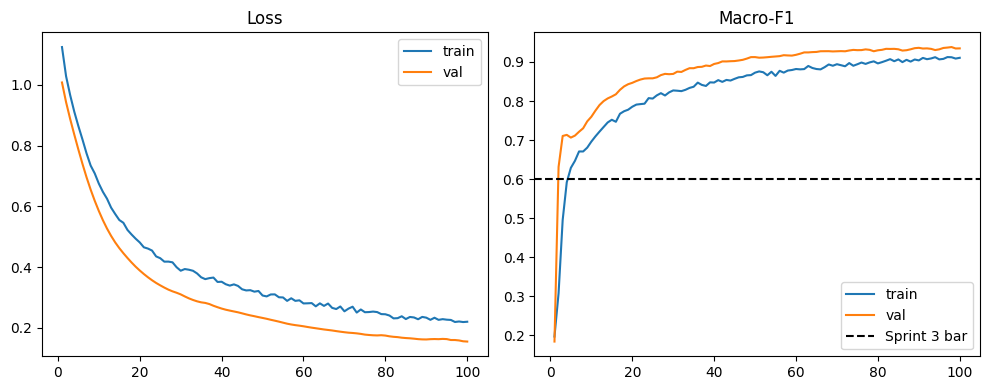

In [10]:
import matplotlib.pyplot as plt

history = result["history"]
epochs = [h["epoch"] for h in history]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(epochs, [h["train_loss"] for h in history], label="train")
ax[0].plot(epochs, [h["val_loss"] for h in history], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(epochs, [h["train_macro_f1"] for h in history], label="train")
ax[1].plot(epochs, [h["val_macro_f1"] for h in history], label="val")
ax[1].axhline(config.GRAPHSAGE_SPRINT3_MACRO_F1_TARGET, color="k", ls="--", label="Sprint 3 bar")
ax[1].set_title("Macro-F1"); ax[1].legend()
plt.tight_layout()
plt.show()

## 4. Hold-out test report

In [11]:
for split in ("train", "val", "test"):
    report = model.evaluate(data, split=split)
    print(f"\n=== {split} ===")
    print("macro_f1:", round(report["macro_f1"], 4), "accuracy:", round(report["accuracy"], 4))
    print("per_class_f1:", {k: round(v, 4) for k, v in report["per_class_f1"].items()})
    print("support:", report["support"])


=== train ===
macro_f1: 0.9449 accuracy: 0.9445
per_class_f1: {'low': 0.9603, 'medium': 0.9258, 'high': 0.9487}
support: {'low': 2475, 'medium': 2523, 'high': 1634}

=== val ===
macro_f1: 0.9382 accuracy: 0.9371
per_class_f1: {'low': 0.9514, 'medium': 0.9164, 'high': 0.9469}
support: {'low': 825, 'medium': 841, 'high': 545}

=== test ===
macro_f1: 0.9401 accuracy: 0.9398
per_class_f1: {'low': 0.9584, 'medium': 0.9191, 'high': 0.9427}
support: {'low': 825, 'medium': 841, 'high': 544}


## 5. Probability vectors for late fusion (Sprint 5)

The Fusion Engine will concatenate these softmax vectors with the U-Net flood probability per parcel. Persist them alongside the checkpoint.

In [12]:
probs = model.predict_proba(data)
preds = model.predict(data)
out_path = Path(CHECKPOINT_DIR) / f"{SETTLEMENT_KEY}_deprivation_probs.pt"
torch.save({"probs": probs, "preds": preds, "y": data.y.cpu()}, out_path)
print("Saved", out_path, "shape", tuple(probs.shape))
print("Sample probs[0]:", probs[0].tolist())

Saved checkpoints/sprint3_graphsage/kibera_deprivation_probs.pt shape (11053, 3)
Sample probs[0]: [0.8768248558044434, 0.12317516654729843, 2.428160450484995e-10]


## Done

- If `meets_sprint3_target` is True, Sprint 3 exit criterion is met on this run.
- Next up: **Sprint 4** extends both heads to Mathare + Mukuru; **Sprint 5** builds the late-fusion policy matrix and validates against NRRP zones; **Sprint 6** adds SHAP / Grad-CAM + Folium dashboard.
- Reminder: re-run Sprint 2 v2 section 5 in Colab with NRRP polygons (or the OSM river-corridor fallback) when you want quantitative flood-label lift before trusting fusion inputs.